&nbsp;

# Up5p lncRNA transcripts Intersect Proecss

- 様々な観点から特徴を捉えた lncRNA transcript について、`upsetplot` で表現する
- NOTE: RNACentral ID が紐づいている ID を今回は後続の解析に使用する！

&nbsp;

### IMPORTANT: Filter 1: `Tag`

- この解析では、lncRNA を、より後続の解析で解釈を容易にするため、GENCODE の [tag](https://www.gencodegenes.org/pages/tags.html) の情報を用いて、ある程度フィルタリングしておく

&nbsp;

### IMPORTANT: Filter 2: RNACentral ID

- 後続の解析を容易にするため、RNACentral ID に紐づいている transcript を対象としている

&nbsp;

In [1]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents
from IPython.display import display

pl.Config.set_tbl_rows(2)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
# https://www.gencodegenes.org/pages/tags.html
list_remove_tag = [
    "sequence_error", # transcript contains at least 1 non-canonical splice junction that is associated with a known or novel genome sequence error.
    "readthrough_transcript", # a transcript that overlaps two or more independent loci but is considered to belong to a third, separate locus.
    "mRNA_start_NF", # the mRNA start could not be confirmed.
    "mRNA_end_NF", # mRNA_end_NF
    "non_canonical_TEC", # the transcript has a non-canonical splice site that needs experimental confirmation.
    "inferred_transcript_model", # transcript model is not supported by a single piece of transcript evidence. May be supported by multiple fragments of transcript evidence or by combining different evidence sources e.g. protein homology, RNA-seq data, published experimental data.
    "non_submitted_evidence", # a splice variant for which supporting evidence has not been submitted to databases, i.e. the model is based on literature or collaborator evidence.
    "NMD_likely_if_extended", # codon if the transcript were longer but cannot currently be annotated as NMD as does not fulfil all criteria - most commonly lack of an intron downstream of the stop codon.
    "low_sequence_quality" # transcript supported by transcript evidence that, while ampping best-in-genome, shows regions of poor sequence quality.
]

&nbsp;

&nbsp;

## 1. up5p lncRNA transcript - CRE pair

- 全ての transcript - CRE pair を読み込む
- 初めから、lncRNA のみ選抜する

In [3]:
up5p_fantabio_all = pl.read_parquet(
    "../../out/fantabio/parquet_file/up5p_transcript_fantabio_v261001.parquet"
).with_columns(
    ((pl.col("transcript_id")) + "-" + (pl.col("cre_id"))).alias("transcript - cre pair")
).filter(
    pl.col("transcript_type") == "lncRNA"
).filter(
    # Drop a row when its tag list shares any element with list_remove_tag
    pl.col("tags").list.set_intersection(list_remove_tag).list.len().fill_null(0) == 0 # NOTE: ここで、list_remove_tag に含まれる tag を持つ row を除外している
).filter(
    pl.col("RNACentral_ID").is_not_null() # NOTE: RNACentral ID が紐づいている ID を今回は後続の解析に使用する！
)

display(up5p_fantabio_all)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,transcript - cre pair
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,str
"""ENST00000850140.1""",317,6,83,311,207,2,42,205,null,null,"""lncRNA""","""ENSG00000310471.1""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""+""",4,"""URS0002A15385""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""overlaps pseudogene""]",2,"""FCHS_28129""","""chr1""",161605881,"""161606178""","""cp1@HSPA7""","[""NR_024151.2""]","""0""",0,"[{""EH38E2843898"",""pELS""}]","[{""CTCF"",1775,[{""SRX10975999"",1775}, {""SRX10976007"",1383}, … {""SRX10976004"",607}]}, {""BCOR"",952,[{""SRX10382399"",952}, {""SRX10382441"",932}]}, … {""PTEN"",504,[{""SRX5416007"",504}]}]","[{""HS_00013426"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}]","[{""hg19::chr1:161575959..161575964,+;hg_6268.1"",""p1@HSPA7""}]",null,1.0,"""ELA""","""255,202,74""","""yellow""","""ENST00000850140.1-FCHS_28129"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000774581.1""",101,57,248,44,34,44,173,-10,null,null,"""lncRNA""","""ENSG00000300853.1""","[""basic"", ""TAGENE""]","""+""",2,"""URS0002A25289""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_400104""","""chr8""",27592922,"""27593122""","""FCHS_400104""","[""ENST00000774579.1""]","""0""",294,"[{""EH38E3824983"",""dELS""}]",null,"[{""HS_00105821"",""NHEK-Epidermal Keratinocyte Primary Cells"",""Skin"",""Skin"",""SVM""}, {""HS_00105822"",""H1 BMP4 Derived Trophoblast Cultured Cells"",""Trophoblast cell"",""Others"",""SVM""}, … {""HS_00105828"",""Breast variant Human Mammary Epithelial Cells (vHMEC)"",""Breast"",""Breast"",""SVM""}]",null,null,0.5,"""ELA""","""255,202,74""","""yellow""","""ENST00000774581.1-FCHS_400104"""


&nbsp;

&nbsp;

&nbsp;

## 1-1: Annotation Remarks

- `annotation_remarks` column including "CLS3 project"
- CLS3 project 由来の transcript の flag を作成する
- about tags: https://www.gencodegenes.org/pages/tags.html

In [4]:
derived_lncrna_cls3_flag = up5p_fantabio_all.filter(
    # Keep rows whose annotation_remarks list contains this exact element
    (pl.col("annotation_remarks").list.contains("CLS3 project"))
    & (pl.col("tags").list.contains("TAGENE"))
).filter(
    # Drop a row when its tag list shares any element with list_remove_tag
    pl.col("tags").list.set_intersection(list_remove_tag).list.len().fill_null(0) == 0 # NOTE: ここで、list_remove_tag に含まれる tag を持つ row を除外している
).filter(
    pl.col("RNACentral_ID").is_not_null() # NOTE: RNACentral ID が紐づいている ID を今回は後続の解析に使用する！
)

display(derived_lncrna_cls3_flag)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,transcript - cre pair
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,str
"""ENST00000850140.1""",317,6,83,311,207,2,42,205,null,null,"""lncRNA""","""ENSG00000310471.1""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""+""",4,"""URS0002A15385""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""overlaps pseudogene""]",2,"""FCHS_28129""","""chr1""",161605881,"""161606178""","""cp1@HSPA7""","[""NR_024151.2""]","""0""",0,"[{""EH38E2843898"",""pELS""}]","[{""CTCF"",1775,[{""SRX10975999"",1775}, {""SRX10976007"",1383}, … {""SRX10976004"",607}]}, {""BCOR"",952,[{""SRX10382399"",952}, {""SRX10382441"",932}]}, … {""PTEN"",504,[{""SRX5416007"",504}]}]","[{""HS_00013426"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}]","[{""hg19::chr1:161575959..161575964,+;hg_6268.1"",""p1@HSPA7""}]",null,1.0,"""ELA""","""255,202,74""","""yellow""","""ENST00000850140.1-FCHS_28129"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000774581.1""",101,57,248,44,34,44,173,-10,null,null,"""lncRNA""","""ENSG00000300853.1""","[""basic"", ""TAGENE""]","""+""",2,"""URS0002A25289""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_400104""","""chr8""",27592922,"""27593122""","""FCHS_400104""","[""ENST00000774579.1""]","""0""",294,"[{""EH38E3824983"",""dELS""}]",null,"[{""HS_00105821"",""NHEK-Epidermal Keratinocyte Primary Cells"",""Skin"",""Skin"",""SVM""}, {""HS_00105822"",""H1 BMP4 Derived Trophoblast Cultured Cells"",""Trophoblast cell"",""Others"",""SVM""}, … {""HS_00105828"",""Breast variant Human Mammary Epithelial Cells (vHMEC)"",""Breast"",""Breast"",""SVM""}]",null,null,0.5,"""ELA""","""255,202,74""","""yellow""","""ENST00000774581.1-FCHS_400104"""


&nbsp;

&nbsp;

## 2. Diff Analysis result (ATAC-seq)

In [5]:
up5p_fantabio_diff_analysis = pl.read_parquet(
    "../../out/ChIP-Atlas_diff/diff_analysis_filter_parquet/transcript_cre/fantabio_HN2_up5p_v261002_diff_analysis_atac.parquet"
).with_columns(
    ((pl.col("transcript_id")) + "-" + (pl.col("cre_id"))).alias("transcript - cre pair")
).filter(
    pl.col("transcript_type") == "lncRNA"
).filter(
    # Drop a row when its tag list shares any element with list_remove_tag
    pl.col("tags").list.set_intersection(list_remove_tag).list.len().fill_null(0) == 0 # NOTE: ここで、list_remove_tag に含まれる tag を持つ row を除外している
).filter(
    pl.col("RNACentral_ID").is_not_null() # NOTE: RNACentral ID が紐づいている ID を今回は後続の解析に使用する！
)

display(up5p_fantabio_diff_analysis)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,cre_start,cre_end,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file,transcript - cre pair
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,i64,i64,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str],str
"""ENST00000729765.1""",315,20,71,295,206,4,41,202,null,null,"""lncRNA""","""ENSG00000295391.1""","[""basic"", ""TAGENE""]","""+""",2,"""URS0002A422B0""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_110516""","""chr13""",31161745,"""31162676""","""cp7@HSPH1""","[""ENST00000954002.1"", ""ENST00000320027.10"", … ""AK311464""]","""0""",0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]","[{""RFX1"",4409,[{""SRX2423398"",4409}, {""SRX2424673"",4103}, … {""SRX5457514"",596}]}, {""HSF1"",3960,[{""SRX16646095"",3960}, {""SRX16646102"",3724}, … {""SRX13845688"",503}]}, … {""ZHX2"",507,[{""SRX3636887"",507}]}]","[{""HS_00184065"",""H1 Derived Neuronal Progenitor Cultured Cells"",""Brain"",""Brain"",""SVM""}, {""HS_00184066"",""H1 BMP4 Derived Trophoblast Cultured Cells"",""Trophoblast cell"",""Others"",""SVM""}, … {""HS_00184072"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}]","[{""hg19::chr13:31735993..31736009,-;hg_136690.1"",""p3@HSPH1""}, {""hg19::chr13:31736027..31736053,-;hg_136691.1"",""p1@HSPH1""}, … {""hg19::chr13:31736780..31736803,+;hg_134654.1"",""hg_134654.1""}]",null,-0.981672,"""PLA""","""0,0,204""","""blue""",31161744,31162676,"[0.05794, 0.040773]","[{31161798,31161852,""chr13""}, {31161701,31161782,""chr13""}]","[1.492452, 1.617098]","[5.5610e-10, 2.6045e-10]","[0.000003, 6.8502e-7]","[""GSE173536_atac_d21_42C_60min"", ""GSE173536_atac_t21_42C_60min""]",2,"[""GSE173536_atac_d21_42C_60min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed"", ""GSE173536_atac_t21_42C_60min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed""]","""ENST00000729765.1-FCHS_110516"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000742045.1""",110,66,230,44,53,33,165,20,"""NUTM2A-AS1""","""HGNC:45161""","""lncRNA""","""ENSG00000223482.11""","[""basic"", ""TAGENE""]","""-""",2,"""URS0002A28948""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_55138""","""chr10""",87342259,"""87342924""","""cp1@LINC00863,cp1@NUTM2A-AS1""","[""ENST00000688214.2"", ""ENST00000742028.1"", … ""BC082979""]","""0""",0,"[{""EH38E2914535"",""PLS""}, {""EH38E4016345"",""PLS""}]","[{""ZNF574"",3512,[{""SRX5457522"",3512}, {""SRX5457521"",2485}, … {""SRX10476700"",1544}]}, {""ZNF143"",3175,[{""SRX2424651"",3175}, {""SRX2424650"",3157}, … {""SRX25254552"",536}]}, … {""KDM2A"",503,[{""SRX3230389"",503}]}]",null,"[{""hg19::chr10:89102091..89102112,-;hg_110435.1"",""p4@NUTM2A-AS1""}, {""hg19::chr10:89102126..89102155,-;hg_110436.1"",""p1@NUTM2A-AS1""}, … {""hg19::chr10:89102332..89102354,-;hg_110438.1"",""p3@NUTM2A-AS1""}]",null,-0.945638,"""PLA""","""0,0,204""","""blue""",87342258,87342924,[0.18018],"[{87342764,87342884,""chr10""}]",[0.987097],[0.000034],[0.000492],"[""GSE101731_atac_hff_44C_120min""]",1,"[""GSE101731_atac_hff_44C_120min_intersecting_human-CREv1.2.1

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 3. Diff Analysis Result (HSF1)

- lncRNAs potentially regulated by the transcription factor HSF1
- FIMO で motif analysis を行った結果、motif が検出された pair を考慮する

In [6]:
up5p_fantabio_diff_analysis_hsf1 = pl.read_parquet(
    "../../out/ChIP-Atlas_diff/diff_analysis_filter_parquet/transcript_cre/fantabio_HN2_up5p_v261008_diff_analysis_chipseq_hsf1.parquet"
).with_columns(
    ((pl.col("transcript_id")) + "-" + (pl.col("cre_id"))).alias("transcript - cre pair")
).filter(
    (pl.col("transcript_type") == "lncRNA")
    & (pl.col("motif_hit").is_not_null())
).filter(
    # Drop a row when its tag list shares any element with list_remove_tag
    pl.col("tags").list.set_intersection(list_remove_tag).list.len().fill_null(0) == 0 # NOTE: ここで、list_remove_tag に含まれる tag を持つ row を除外している
).filter(
    pl.col("RNACentral_ID").is_not_null() # NOTE: RNACentral ID が紐づいている ID を今回は後続の解析に使用する！
)


display(up5p_fantabio_diff_analysis_hsf1)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,cre_start,cre_end,motif_hit,n_motif_hit,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file,transcript - cre pair
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,i64,i64,list[struct[9]],u32,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str],str
"""ENST00000850140.1""",317,6,83,311,207,2,42,205,null,null,"""lncRNA""","""ENSG00000310471.1""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""+""",4,"""URS0002A15385""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""overlaps pseudogene""]",2,"""FCHS_28129""","""chr1""",161605881,"""161606178""","""cp1@HSPA7""","[""NR_024151.2""]","""0""",0,"[{""EH38E2843898"",""pELS""}]","[{""CTCF"",1775,[{""SRX10975999"",1775}, {""SRX10976007"",1383}, … {""SRX10976004"",607}]}, {""BCOR"",952,[{""SRX10382399"",952}, {""SRX10382441"",932}]}, … {""PTEN"",504,[{""SRX5416007"",504}]}]","[{""HS_00013426"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}]","[{""hg19::chr1:161575959..161575964,+;hg_6268.1"",""p1@HSPA7""}]",null,1.0,"""ELA""","""255,202,74""","""yellow""",161605880,161606178,"[{""MA0486.1"",""HSF1"",214,228,""-"",12.4225,0.0000193,0.383,""CTTCCCGCACCTTCC""}, {""MA0486.2"",""HSF1"",31,43,""+"",9.69355,0.0000269,0.705,""AGCTAGAACCTTC""}, … {""MA0486.1"",""HSF1"",30,44,""+"",10.8732,0.0000478,0.478,""GAGCTAGAACCTTCC""}]",5,[0.395973],"[{161606060,161606234,""chr1""}]",[2.465951],[0.000006],[0.000045],"[""pair1_GSE38901_hsf1_mcf10a_hs_42C_60min""]",1,"[""pair1_GSE38901_hsf1_mcf10a_hs_42C_60min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed""]","""ENST00000850140.1-FCHS_28129"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000710875.1""",84,40,282,44,53,31,167,22,"""MALAT1""","""HGNC:29665""","""lncRNA""","""ENSG00000251562.13""","[""RNA_Seq_supported_only""]","""+""",1,"""URS00027F7F58""","""ENSEMBL_GENCODE""","[""polya_site"", ""polya_signal""]","""havana_homo_sapiens""","[""RNA-Seq supported only""]",1,"""FCHS_73697""","""chr11""",65498613,"""65499245""","""cp12@MALAT1""","[""ENST00000710950.1"", ""ENST00000620902.1"", … ""BC104662""]","""0""",0,"[{""EH38E2964428"",""pELS""}, {""EH38E2964429"",""PLS""}, {""EH38E2964430"",""pELS""}]","[{""TBP"",2781,[{""SRX482859"",2781}, {""SRX9498732"",1936}, … {""SRX4367421"",537}]}, {""NELFCD"",2621,[{""SRX15147203"",2621}, {""SRX7677719"",2527}, … {""SRX19246543"",607}]}, … {""MECOM"",500,[{""SRX15152338"",500}]}]","[{""HS_00156151"",""H1 Derived Neuronal Progenitor Cultured Cells"",""Brain"",""Brain"",""SVM""}, {""HS_00156152"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, … {""HS_00156154"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}]","[{""hg19::chr11:65266090..65266102,+;hg_115162.1"",""p11@MALAT1""}, {""hg19::chr11:65266121..65266168,+;hg_115163.1"",""p6@MALAT1""}, … {""hg19::chr11:65266507..65266522,+;hg_115164.1"",""p1@MALAT1""}]",null,0.99986,"""PLA""","""204,0,0""","""red""",65498612,65499245,"[{""MA0486.1"",""HSF1"",286,300,""-"",16.5352,0.000001,0.164,""TTTCTAGATTTTTCT""}, {""MA0486.2"",""HSF1"",287,299,""-"",14.3548,0.000003,0.431,""TTCTAGATTTTTC""}]",2,[0.67

&nbsp;

&nbsp;

## 4. divergent lncRNA

- 行が、cre - protein-coding transcript - lncRNA transcript になっているので注意

In [7]:
up5p_fantabio_cre_divergent = pl.read_parquet(
    "../../out/transcript_classification/divergent_transcript/pc_common_cre_lncRNA_divergent/up5p_fantabio_pc_common_cre_lncRNA_divergent.parquet"
).with_columns(
    ((pl.col("lncrna_transcript_id")) + "-" + (pl.col("cre_id"))).alias("transcript - cre pair")
).filter(
    # tags is the list field inside lncrna_transcript_info
    pl.col("lncrna_transcript_info").struct.field("tags").list.set_intersection(list_remove_tag).list.len().fill_null(0) == 0 # NOTE: ここで、list_remove_tag に含まれる tag を持つ row を除外している
).filter(
    # RNACentral_ID lives inside the struct, not as a top-level column
    pl.col("lncrna_transcript_info").struct.field("RNACentral_ID").is_not_null() # NOTE: RNACentral ID が紐づいている ID を今回は後続の解析に使用する！
)

display(up5p_fantabio_cre_divergent)

cre_id,cre_name,fantabio_cre_class,cre_chrom,cre_chrom_start,cre_chrom_end,directionality,pc_transcript_distance,screen_ccres,fantom5_enhancers,pc_transcript_id,pc_HN2,pc_transcript_strand,pc_transcript_info,lncrna_transcript_distance,lncrna_transcript_id,lncrna_HN2,lncrna_transcript_strand,lncrna_transcript_info,strand_type,pc_lncrna_HN2,id_correspondence_flag,Transcript_classification_codes,FANTOM-CAT_transcript_lv4_stringent,gene class,fantomcat_transcript_info,screen_promoter_support,ensembl_promoter_window_support,fantomcat_stringent_support,transcript - cre pair
str,str,str,str,i64,i64,f64,i64,list[struct[2]],list[struct[1]],str,i64,str,struct[5],i64,str,i64,str,struct[5],str,i64,str,str,str,str,list[struct[7]],str,str,str,str
"""FCHS_110516""","""cp7@HSPH1""","""PLA""","""chr13""",31161745,31162676,-0.981672,0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]",null,"""ENST00000954002.1""",263,"""-""","{""ENSG00000120694.21"",""HSPH1"",""protein_coding"",null,[""basic"", ""TAGENE"", ""CCDS""]}",0,"""ENST00000729765.1""",295,"""+""","{""ENSG00000295391.1"",null,""lncRNA"",""URS0002A422B0"",[""basic"", ""TAGENE""]}","""opposite strand""",558,"""4_equal_fantom_native""","""=""","""FTMT25200000861.1""","""uncertain coding""","[{""CATG00000014230.1"",""promoter"",138.6,730.6,null,null,1.3800e-10}]","""supported by SCREEN""","""supported by Ensembl/GENCODE p…","""not supported by FANTOM-CAT (s…","""ENST00000729765.1-FCHS_110516"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_177259""","""cp1@SPAG9""","""PLA""","""chr17""",51120666,51121355,-0.977787,0,"[{""EH38E3230875"",""PLS""}, {""EH38E3230876"",""pELS""}, {""EH38E4165335"",""PLS""}]","[{[""chr17:51121243-51122181""]}]","""ENST00000933646.1""",44,"""-""","{""ENSG00000008294.23"",""SPAG9"",""protein_coding"",null,[""basic"", ""GENCODE_Primary"", … ""appris_alternative_1""]}",0,"""ENST00000831795.1""",44,"""+""","{""ENSG00000308112.1"",null,""lncRNA"",""URS0002A38AD4"",[""basic"", ""Ensembl_canonical"", … ""TAGENE""]}","""opposite strand""",88,"""4_equal_fantom_native""","""=""","""ENCT00000176518.1""","""lncRNA, divergent""","[{""CATG00000031741.1"",""promoter"",347.8,108.8,null,9.7270e-33,5.3900e-42}]","""supported by SCREEN""","""supported by Ensembl/GENCODE p…","""supported by FANTOM-CAT (strin…","""ENST00000831795.1-FCHS_177259"""


&nbsp;

&nbsp;

## 5. enhancer-derived lncRNA

- ENCODE-rE2G で検出されたシスエレメントを近傍に持つ lncRNA

In [8]:
e_derived_lncRNA = pl.read_parquet(
    "../../out/transcript_classification/enhancer_derived_lncRNA/up5p_enhancer_derived_lncRNA_v261010.parquet"
).with_columns(
    ((pl.col("e_transcript_id")) + "-" + (pl.col("cre_id"))).alias("transcript - cre pair")
).filter(
    pl.col("e_transcript_type") == "lncRNA"
).filter(
    # Drop a row when its tag list shares any element with list_remove_tag
    pl.col("e_tags").list.set_intersection(list_remove_tag).list.len().fill_null(0) == 0 # NOTE: ここで、list_remove_tag に含まれる tag を持つ row を除外している
).filter(
    pl.col("e_RNACentral_ID").is_not_null() # NOTE: RNACentral ID が紐づいている ID を今回は後続の解析に使用する！
)

display(e_derived_lncRNA)

cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean,e_transcript_id,e_HN2,e_transcript_type,e_gene_id,e_gene_symbol,e_strand,e_RNACentral_ID,e_annotation_remarks,e_tags,transcript - cre pair
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64,str,i64,str,str,str,str,str,list[str],list[str],str
"""FCHS_94451""","""FCHS_94451""","""PLA""","""FCHS_94499""","""cp1@ATG101""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.778816, 0.778816, … 0.904984]",0.767913,0.904984,0.806297,"[0.355003, 0.189876, … 0.526484]",0.189876,0.774307,0.408416,"""ENST00000812391.1""",128,"""lncRNA""","""ENSG00000305684.1""",null,"""-""","""URS0002A236EE""","[""CLS3 project""]","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""ENST00000812391.1-FCHS_94451"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_265630""","""cp2@LOC105369306""","""ELA""","""FCHS_265830""","""cp4@RIPPLY3""","""PLA""","[""GSE105028_hESC_42C_60min""]",1,[1.0],1.0,1.0,1.0,[0.27554],0.27554,0.27554,0.27554,"""ENST00000422473.2""",51,"""lncRNA""","""ENSG00000233393.3""",null,"""+""","""URS0002A57053""","[""CLS3 project""]","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""ENST00000422473.2-FCHS_265630"""


&nbsp;

&nbsp;

&nbsp;

## Upset Plot

- ここで可視化されるのは、以下の基準をみたした lncRNA - CRE pair のみである

&nbsp;

### IMPORTANT: Filter 1: `Tag`

- この解析では、lncRNA を、より後続の解析で解釈を容易にするため、GENCODE の [tag](https://www.gencodegenes.org/pages/tags.html) の情報を用いて、ある程度フィルタリングしておく

&nbsp;

### IMPORTANT: Filter 2: RNACentral ID

- 後続の解析を容易にするため、RNACentral ID に紐づいている transcript を対象としている

&nbsp;

In [9]:
transcript_cre_contents = {
    "all pairs": up5p_fantabio_all.select("transcript - cre pair").unique().to_series().to_list(),
    "derived from CLS3 project": derived_lncrna_cls3_flag.select("transcript - cre pair").unique().to_series().to_list(),
    "Diff Analysis (ATAC-seq)": up5p_fantabio_diff_analysis.select("transcript - cre pair").unique().to_series().to_list(),
    "Diff Analysis (HSF1)": up5p_fantabio_diff_analysis_hsf1.select("transcript - cre pair").unique().to_series().to_list(),
    "divergent": up5p_fantabio_cre_divergent.select("transcript - cre pair").unique().to_series().to_list(),
    "enhancer-derived": e_derived_lncRNA.select("transcript - cre pair").unique().to_series().to_list(),
}

upset_data = from_contents(transcript_cre_contents)

upset_data.to_csv(
    f"../../out/transcript_classification/upsetplot/up5p_transcript_upset_data_v261010.tsv",
    index=True,
    sep="\t"
)

display(upset_data)

/usr/local/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


id
all pairs derived from CLS3 project Diff Analysis (ATAC-seq) Diff Analysis (HSF1) divergent enhancer-derived                               
True      True                      False                    False                False     False             ENST00000762829.1-FCHS_442950
          False                     False                    False                False     True              ENST00000607794.2-FCHS_149384
          True                      False                    False                False     False             ENST00000830147.1-FCHS_318953
                                                                                            False             ENST00000773409.1-FCHS_199701
                                                                                            False              ENST00000810898.1-FCHS_17158
...                                                                                                                                     ...
                                                                                            False             ENST00000772900.1-FCHS_130885
          False                     False                    False                False     True              ENST00000423178.6-FCHS_466850
          True                      False                    False                False     False             ENST00000783516.1-FCHS_110693
                                                                                            False             ENST00000725945.1-FCHS_401721
                                                                                            True              ENST00000757107.1-FCHS_395597

[8607 rows x 1 columns]

/usr/local/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

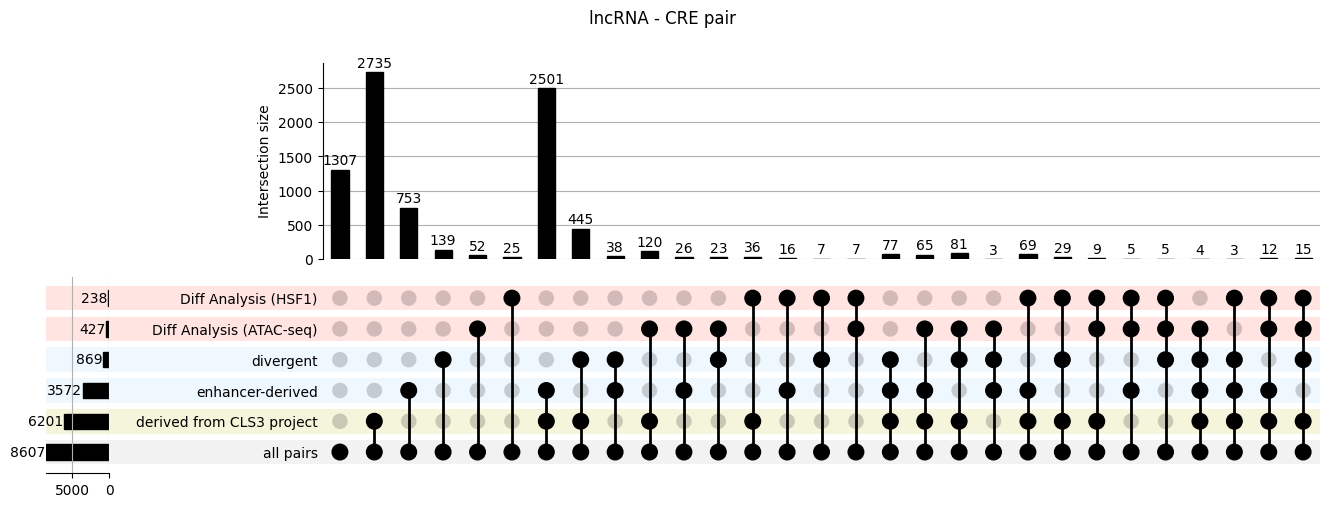

In [11]:
upset_plot = UpSet(
    upset_data,
    orientation='horizontal',
    show_counts="{:d}",
    subset_size='count',
    include_empty_subsets = False
)

upset_plot.style_categories(
    ["Diff Analysis (ATAC-seq)", "Diff Analysis (HSF1)"],
    shading_facecolor="mistyrose",
)

upset_plot.style_categories(
    ["divergent", "enhancer-derived"],
    shading_facecolor="aliceblue",
)

upset_plot.style_categories(
    ["derived from CLS3 project"],
    shading_facecolor="beige",
)


# Use the default dpi here so that the label width is estimated correctly
fig = plt.figure(figsize=(14, 8))
upset_plot.plot(fig=fig)
fig.suptitle("lncRNA - CRE pair")
# Apply the high resolution only when saving
fig.savefig(
    "../../out/transcript_classification/upsetplot/up5p_transcript_upset_plot_v261010.png",
    dpi=500,
    bbox_inches="tight"
)
plt.show()

/usr/local/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

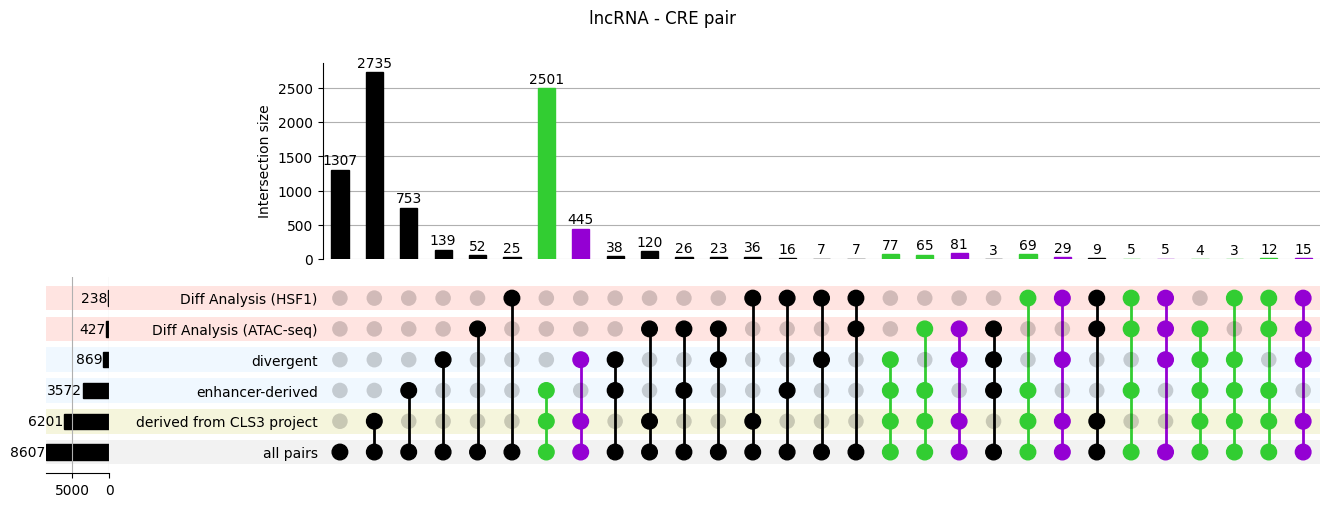

In [21]:
upset_plot_v2 = UpSet(
    upset_data,
    orientation='horizontal',
    show_counts="{:d}",
    subset_size='count',
    include_empty_subsets = False
)

upset_plot_v2.style_categories(
    ["Diff Analysis (ATAC-seq)", "Diff Analysis (HSF1)"],
    shading_facecolor="mistyrose",
)

upset_plot_v2.style_categories(
    ["divergent", "enhancer-derived"],
    shading_facecolor="aliceblue",
)

upset_plot_v2.style_categories(
    ["derived from CLS3 project"],
    shading_facecolor="beige",
)

upset_plot_v2.style_subsets(
    present=["Diff Analysis (HSF1)", "Diff Analysis (ATAC-seq)", "divergent"],
    facecolor="darkviolet",
)

upset_plot_v2.style_subsets(
    present=["derived from CLS3 project", "divergent"],
    facecolor="darkviolet",
)

upset_plot_v2.style_subsets(
    present=["Diff Analysis (HSF1)", "Diff Analysis (ATAC-seq)", "enhancer-derived"],
    facecolor="limegreen",
)

upset_plot_v2.style_subsets(
    present=["derived from CLS3 project", "enhancer-derived"],
    facecolor="limegreen",
)


# Use the default dpi here so that the label width is estimated correctly
fig = plt.figure(figsize=(14, 8))
upset_plot_v2.plot(fig=fig)
fig.suptitle("lncRNA - CRE pair")
# Apply the high resolution only when saving
fig.savefig(
    "../../out/transcript_classification/upsetplot/up5p_transcript_upset_plot_v2_v261010.png",
    dpi=500,
    bbox_inches="tight"
)
plt.show()